In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

# Load data
ames_data = pd.read_csv("../datasets/fe-course-data/ames.csv")
ames_data.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YearSold,SaleType,SaleCondition,SalePrice
0,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,141.0,31770.0,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,0.0,No_Pool,No_Fence,NaN,0.0,5,2010,WD,Normal,215000
1,One_Story_1946_and_Newer_All_Styles,Residential_High_Density,80.0,11622.0,Pave,No_Alley_Access,Regular,Lvl,AllPub,Inside,...,0.0,No_Pool,Minimum_Privacy,NaN,0.0,6,2010,WD,Normal,105000
2,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,81.0,14267.0,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,0.0,No_Pool,No_Fence,Gar2,12500.0,6,2010,WD,Normal,172000
3,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,93.0,11160.0,Pave,No_Alley_Access,Regular,Lvl,AllPub,Corner,...,0.0,No_Pool,No_Fence,NaN,0.0,4,2010,WD,Normal,244000
4,Two_Story_1946_and_Newer,Residential_Low_Density,74.0,13830.0,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Inside,...,0.0,No_Pool,Minimum_Privacy,NaN,0.0,3,2010,WD,Normal,189900


In [2]:
### Utility functions
import numpy as np
from sklearn.feature_selection import mutual_info_regression

def make_mi_scores(X, y):
    X = X.copy()
    for colname in X.select_dtypes(["object", "category"]):
        X[colname], _ = X[colname].factorize()
    # All discrete features should now have integer dtypes
    discrete_features = [pd.api.types.is_integer_dtype(t) for t in X.dtypes]
    mi_scores = mutual_info_regression(X, y, discrete_features=discrete_features, random_state=0)
    mi_scores = pd.Series(mi_scores, name="MI Scores", index=X.columns)
    mi_scores = mi_scores.sort_values(ascending=False)
    return mi_scores

def plot_mi_scores(scores):
    scores = scores.sort_values(ascending=True)
    width = np.arange(len(scores))
    ticks = list(scores.index)
    plt.barh(width, scores)
    plt.yticks(width, ticks)
    plt.title("Mutual Information Scores")

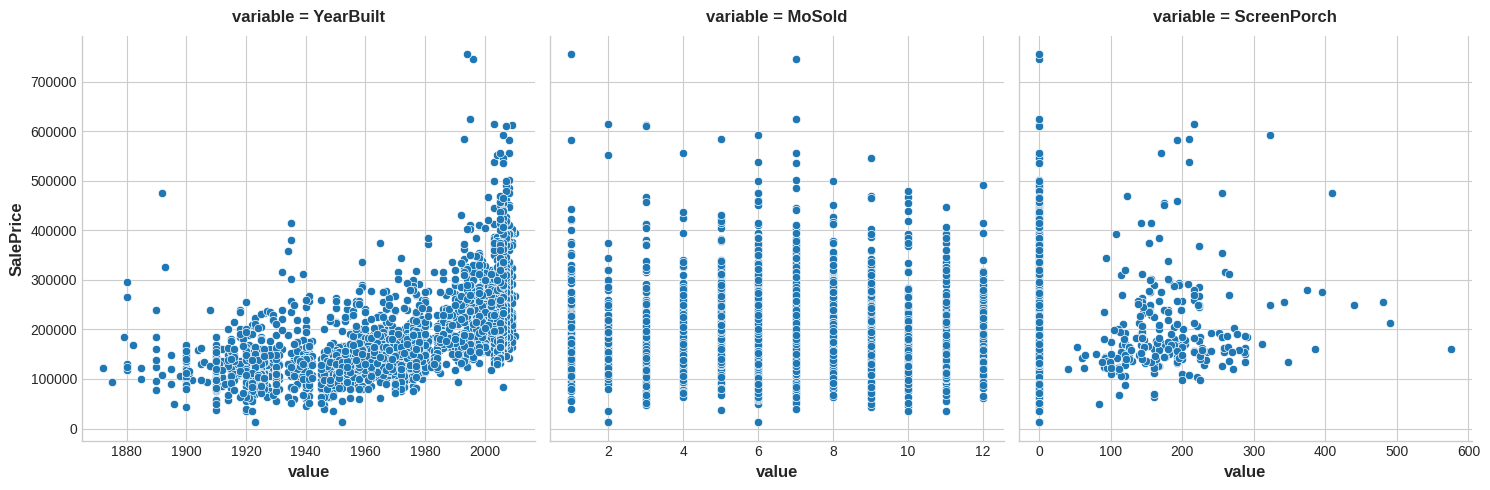

In [3]:
features = ["YearBuilt", "MoSold", "ScreenPorch"]
sns.relplot(
    x="value", y="SalePrice", col="variable", 
    data=ames_data.melt(id_vars="SalePrice", value_vars=features), 
    facet_kws=dict(sharex=False),
);

In [4]:
from IPython.display import display, Markdown

content = f"""
**Q**: **Based on the plots, which feature do you think would have the highest mutual information 
with SalePrice?**<br>
**A**: Based on the plots, `YearBuilt` should have the highest MI score since knowing the year tends 
to constrain SalePrice to a smaller range of possible values. This is generally not the case for MoSold, 
however. Finally, since ScreenPorch is usually just one value, 0, on average it won't tell you much about 
SalePrice (though more than MoSold) .
"""

display(Markdown(content))


**Q**: **Based on the plots, which feature do you think would have the highest mutual information 
with SalePrice?**<br>
**A**: Based on the plots, `YearBuilt` should have the highest MI score since knowing the year tends 
to constrain SalePrice to a smaller range of possible values. This is generally not the case for MoSold, 
however. Finally, since ScreenPorch is usually just one value, 0, on average it won't tell you much about 
SalePrice (though more than MoSold) .


In [5]:
# Separate predictors from target
X = ames_data.copy()
y = X.pop('SalePrice')

# Compute Mutual Information scores
mi_scores = make_mi_scores(X, y)

In [6]:
mi_scores.head(20)

OverallQual     0.581262
Neighborhood    0.569813
GrLivArea       0.496909
YearBuilt       0.437939
GarageArea      0.415014
TotalBsmtSF     0.390280
GarageCars      0.381467
FirstFlrSF      0.368825
BsmtQual        0.364779
KitchenQual     0.326194
ExterQual       0.322390
YearRemodAdd    0.315402
MSSubClass      0.287131
GarageFinish    0.265440
FullBath        0.251693
Foundation      0.236115
LotFrontage     0.233334
GarageType      0.226117
FireplaceQu     0.221955
SecondFlrSF     0.200658
Name: MI Scores, dtype: float64

In [7]:
mi_scores.tail(20)

ExterCond           0.020934
KitchenAbvGr        0.017677
BsmtHalfBath        0.013719
LotConfig           0.013637
ScreenPorch         0.012981
PoolArea            0.012831
MiscVal             0.010997
LowQualFinSF        0.009328
Heating             0.007622
Functional          0.006380
MiscFeature         0.004322
Street              0.003381
Condition2          0.003176
RoofMatl            0.002620
PoolQC              0.001370
Utilities           0.000291
LandSlope           0.000000
BsmtFinSF2          0.000000
Threeseasonporch    0.000000
MoSold              0.000000
Name: MI Scores, dtype: float64

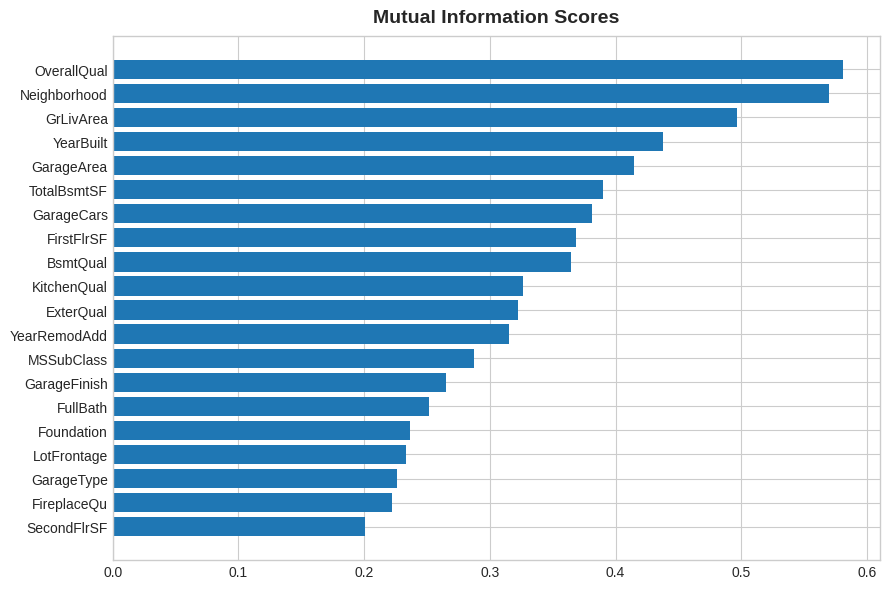

In [8]:
plt.figure(dpi=100, figsize=(9, 6))
plot_mi_scores(mi_scores.head(20))

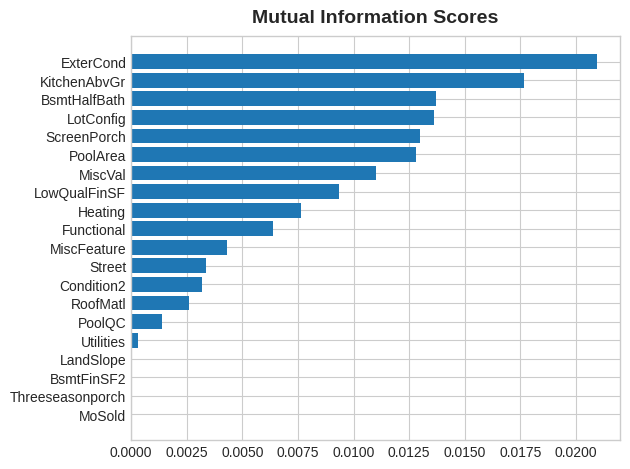

In [9]:
plot_mi_scores(mi_scores.tail(20))

In [10]:
content = f"""
**Q**: **Do the scores seem reasonable? Do the high scoring features represent things you'd think most 
people would value in a home? Do you notice any themes in what they describe?**

**A**: Some common themes among most of these features are:
- _Location_: `Neighborhood`
- _Size_: all of the `Area` and `SF` features, and counts like `FullBath` and `GarageCars`
- _Quality_: all of the `Qual` features
- _Year_: `YearBuilt` and `YearRemodAdd`
- _Types_: descriptions of features and styles like `Foundation` and `GarageType`

These are all the kinds of features you'll commonly see in real-estate listings (like on Zillow), 
It's good then that our mutual information metric scored them highly. On the other hand, the lowest 
ranked features seem to mostly represent things that are rare or exceptional in some way, and so wouldn't 
be relevant to the average home buyer.
"""

display(Markdown(content))


**Q**: **Do the scores seem reasonable? Do the high scoring features represent things you'd think most 
people would value in a home? Do you notice any themes in what they describe?**

**A**: Some common themes among most of these features are:
- _Location_: `Neighborhood`
- _Size_: all of the `Area` and `SF` features, and counts like `FullBath` and `GarageCars`
- _Quality_: all of the `Qual` features
- _Year_: `YearBuilt` and `YearRemodAdd`
- _Types_: descriptions of features and styles like `Foundation` and `GarageType`

These are all the kinds of features you'll commonly see in real-estate listings (like on Zillow), 
It's good then that our mutual information metric scored them highly. On the other hand, the lowest 
ranked features seem to mostly represent things that are rare or exceptional in some way, and so wouldn't 
be relevant to the average home buyer.



`BldgType` describes the broad structure of the dwelling in five categories:
- 1Fam:	Single-family Detached	
- 2FmCon: Two-family Conversion; originally built as one-family dwelling
- Duplx: Duplex
- TwnhsE: Townhouse End Unit
- TwnhsI: Townhouse Inside Unit


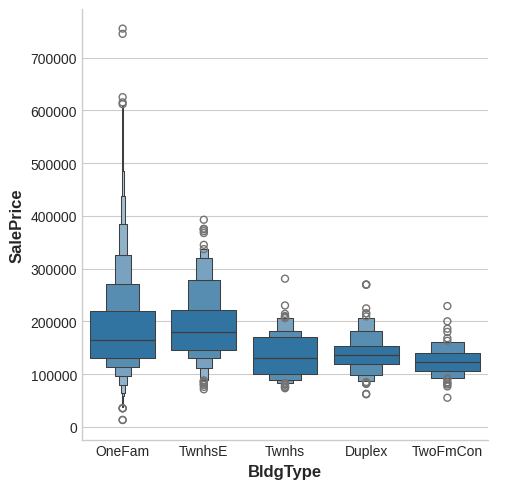

In [14]:
content = f"""
`BldgType` describes the broad structure of the dwelling in five categories:
- 1Fam:	Single-family Detached	
- 2FmCon: Two-family Conversion; originally built as one-family dwelling
- Duplx: Duplex
- TwnhsE: Townhouse End Unit
- TwnhsI: Townhouse Inside Unit
"""
display(Markdown(content))
sns.catplot(x="BldgType", y="SalePrice", data=ames_data, kind="boxen");

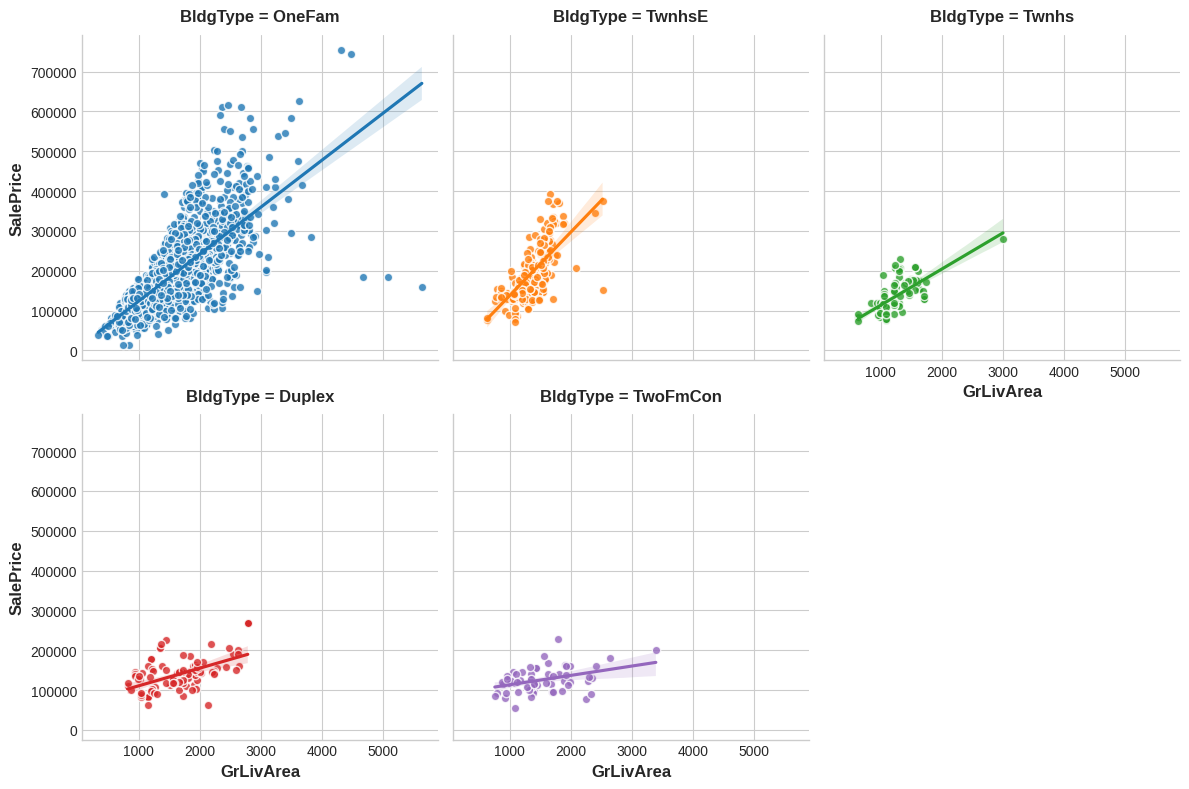

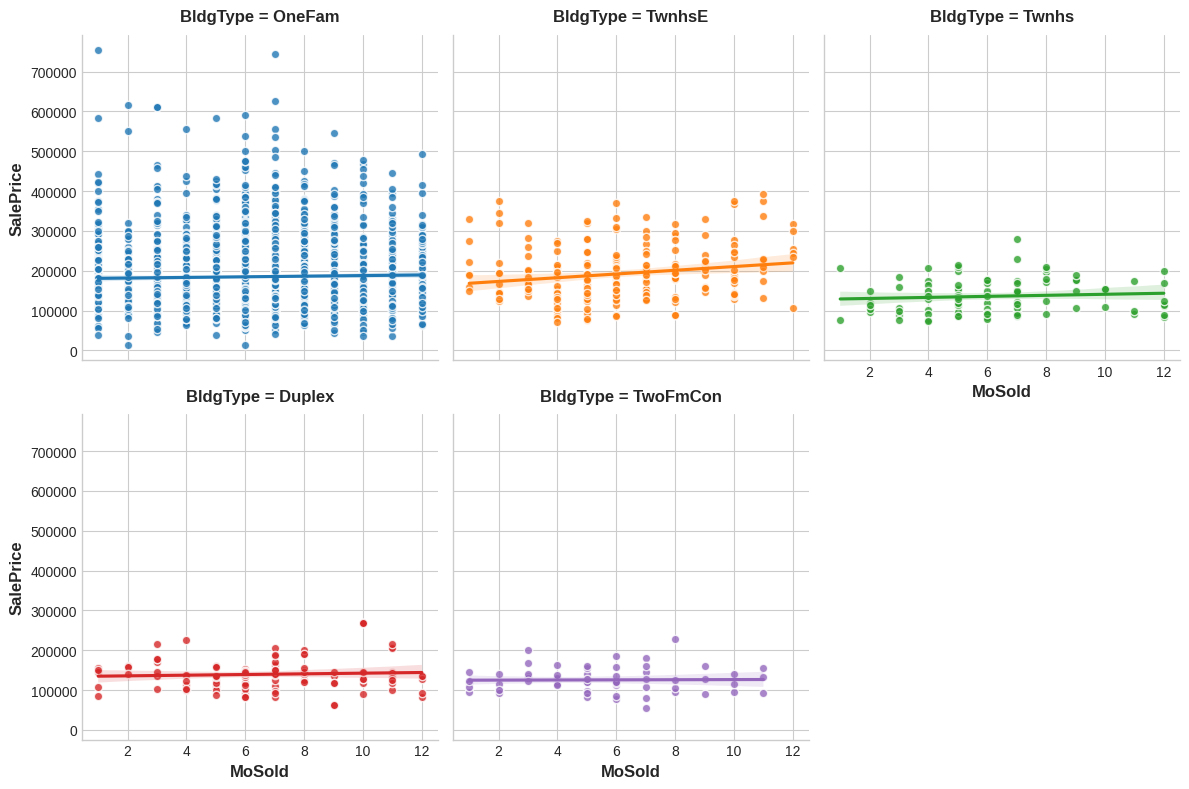

In [16]:
for feature in ["GrLivArea", "MoSold"]:
    sns.lmplot(
        x=feature, y="SalePrice", hue="BldgType", col="BldgType",
        data=ames_data, scatter_kws={"edgecolor": 'w'}, col_wrap=3, height=4,
    )

In [17]:
content = f"""
**Q**: **From the plots, does `BldgType` seem to exhibit an interaction effect with either 
`GrLivArea` or `MoSold`?**<br>
**A**: The trends lines within each category of `BldgType` are clearly very different, indicating an 
interaction between these features. Since knowing `BldgType` tells us more about how `GrLivArea` 
relates to `SalePrice`, we should consider including `BldgType` in our feature set.<br>
The trend lines for `MoSold`, however, are almost all the same. This feature hasn't become more informative 
for knowing `BldgType`.
"""
display(Markdown(content))


**Q**: **From the plots, does `BldgType` seem to exhibit an interaction effect with either 
`GrLivArea` or `MoSold`?**<br>
**A**: The trends lines within each category of `BldgType` are clearly very different, indicating an 
interaction between these features. Since knowing `BldgType` tells us more about how `GrLivArea` 
relates to `SalePrice`, we should consider including `BldgType` in our feature set.<br>
The trend lines for `MoSold`, however, are almost all the same. This feature hasn't become more informative 
for knowing `BldgType`.


In [18]:
mi_scores.head(10)

OverallQual     0.581262
Neighborhood    0.569813
GrLivArea       0.496909
YearBuilt       0.437939
GarageArea      0.415014
TotalBsmtSF     0.390280
GarageCars      0.381467
FirstFlrSF      0.368825
BsmtQual        0.364779
KitchenQual     0.326194
Name: MI Scores, dtype: float64